# Bước 1: hiệu chỉnh recency bias hậu kỳ (logit adjustment)

Confusion matrix cho thấy lớp vừa học hút báo động giả từ normal (108 mẫu normal thành speed ở phase 2, 209 mẫu normal thành combined ở phase 5). Giả thuyết: sau mỗi lần expand, tập huấn luyện gồm dữ liệu mới cộng replay có tỷ lệ lớp rất khác dữ liệu thật, nên mô hình học lệch prior về phía lớp mới.

Notebook này kiểm tra giả thuyết **mà không huấn luyện lại**, trên các checkpoint có sẵn:

1. Dựng lại chính xác phân phối nhãn của tập huấn luyện ở từng phase (dữ liệu mới + replay, cùng seed như script).
2. Lấy logits của mô hình trên tập val và test của từng phase.
3. Hai cách hiệu chỉnh, cả hai chỉ dùng tập **val**:
   - **Prior correction**: `logits + τ · (log π_val − log π_train)`. Với τ = 1, đây là hiệu chỉnh Bayes khi prior thay đổi. τ được chọn trên val, một giá trị chung cho mọi phase.
   - **Bias fit**: học một vector bias (mỗi lớp một số) bằng cách tối thiểu cross-entropy trên val. Không giả định gì về nguyên nhân.
4. Đánh giá trên **test**: F1, normal_FPR, tỷ lệ phát hiện attack, F1 từng lớp, confusion matrix trước và sau.

**Cách đọc:** nếu prior correction gỡ được phần lớn báo động giả, và bias học được đi cùng chiều với log(π_val / π_train), thì recency bias do lệch prior là nguyên nhân chính. Khi đó nên đưa hiệu chỉnh vào lúc huấn luyện (bước 2).

Không dùng biến thể "balanced" (`logits − τ · log π_train`): nó nhắm tới phân phối đều, nên đẩy dự đoán ra khỏi normal và làm tăng báo động giả, ngược với điều IDS cần.

## 1. Cấu hình

In [1]:
PROJECT_ROOT = None        # None: tự tìm (thư mục chứa train_continual_clean.py)
DATA_DIR = "./data/2011-chevrolet-impala/preprocessed"
RUN_DIR = "./save/clean/impala/cosine_s42"
ARCH = "cosine"
GPU = 0
BATCH_SIZE = 256
RECOMPUTE = False                      # True: tính lại logits dù đã có cache
TAUS = [round(0.1 * i, 1) for i in range(0, 21)]   # lưới τ từ 0 đến 2
CM_PHASES = ["phase2", "phase5"]       # các phase vẽ confusion matrix trước/sau

## 2. Import

In [2]:
import os, sys, json, re
from pathlib import Path

# Tìm thư mục gốc project (nơi có train_continual_clean.py), bắt đầu từ thư mục notebook
# rồi đi ngược lên. Mọi đường dẫn "./data", "./save" trong cấu hình tính từ thư mục gốc.
NOTEBOOK_DIR = Path.cwd()
if "ROOT" not in globals():          # tránh tính lại khi chạy lại ô này
    if PROJECT_ROOT:
        ROOT = Path(PROJECT_ROOT).resolve()
    else:
        ROOT = next((p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
                     if (p / "train_continual_clean.py").exists()), None)
        if ROOT is None:
            raise FileNotFoundError("Không tìm thấy train_continual_clean.py ở thư mục notebook "
                                    "hoặc các thư mục cha; đặt PROJECT_ROOT thủ công")
    os.chdir(ROOT)
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from train_continual_clean import (DEFAULT_PHASES, VARIANT_PHASES, filter_by_labels,
                                   split_dos_windows, per_class_f1)
from utils import (WindowDataset, collate_fn, compute_metrics, get_class_names,
                   load_metadata, load_windows)

DEVICE = torch.device(f"cuda:{GPU}" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = get_class_names()
pd.set_option("display.precision", 4)
print("device:", DEVICE)

project root: /home/hieutt/MoE-IVN-IDS
device: cuda:0


In [ ]:
from networks.moe_ivn_ids import MoEIVNIDSv2
try:
    from networks.moe_ivn_ids_cosine import MoEIVNIDS as MoEIVNIDSCosine
except ImportError:
    MoEIVNIDSCosine = None
try:
    from networks.dense_ivn_ids import DenseIVNIDS
except ImportError:
    try:
        from dense_ivn_ids import DenseIVNIDS
    except ImportError:
        DenseIVNIDS = None


def count_experts(sd):
    return len({k.split(".")[2] for k in sd if k.startswith("moe.experts.")})


def _num_classes(sd, default=10):
    idx = [int(m.group(1)) for k in sd if (m := re.match(r"classifier\.(\d+)\.weight$", k))]
    return sd[f"classifier.{max(idx)}.weight"].shape[0] if idx else default


def build_from_state(sd, arch, saved_args=None):
    """Dựng mô hình từ chính kích thước tensor trong checkpoint, rồi nạp strict.
    arch: "dense" | "v2" (cả v1 = v2 không bật cờ nào) | "cosine"."""
    saved_args = saved_args or {}
    vocab, embed_dim = sd["id_embedding.weight"].shape
    dropout = saved_args.get("dropout", 0.2)

    if arch == "dense":
        assert DenseIVNIDS is not None, "Không import được DenseIVNIDS"
        hidden, in_dim = sd["projection.0.weight"].shape
        model = DenseIVNIDS(vocab_size=vocab, num_features=in_dim - embed_dim,
                            embed_dim=embed_dim, num_classes=_num_classes(sd),
                            dense_hidden=hidden, out_dim=sd["projection.3.weight"].shape[0],
                            cls_hidden=sd["classifier.0.weight"].shape[0], dropout=dropout)
    else:
        expert0 = [k for k in sd if k.startswith("moe.experts.0.")]
        if any("spline" in k or "base_weight" in k for k in expert0):
            raise NotImplementedError("Checkpoint dùng KAN expert, notebook này chưa hỗ trợ")
        hidden, in_dim = sd["moe.experts.0.net.0.weight"].shape
        common = dict(vocab_size=vocab, num_features=in_dim - embed_dim, embed_dim=embed_dim,
                      num_experts=count_experts(sd), top_k=saved_args.get("top_k", 2),
                      moe_out_dim=sd["moe.experts.0.net.3.weight"].shape[0], dropout=dropout)
        if arch == "cosine":
            assert MoEIVNIDSCosine is not None, "Không import được moe_ivn_ids_cosine"
            model = MoEIVNIDSCosine(**common)
        elif arch in ("v1", "v2"):
            flags = dict(
                use_residual="residual_proj.weight" in sd,
                attention_readout=any(k.startswith("readout_attn.") for k in sd),
                light_classifier=not any(k.startswith("classifier.6.") for k in sd))
            model = MoEIVNIDSv2(**common, expert_hidden=hidden, num_classes=_num_classes(sd),
                                cls_hidden=sd["classifier.0.weight"].shape[0], **flags)
        else:
            raise ValueError(f"arch không hợp lệ: {arch}")
    model.load_state_dict(sd, strict=True)
    return model.eval()

In [4]:
import torch.nn.functional as F
NC = len(CLASS_NAMES)
RUN = Path(RUN_DIR)
SAVED_ARGS = torch.load(RUN / "phase1_best.pth", map_location="cpu", weights_only=False).get("args", {})
PHASE_CONFIG = SAVED_ARGS.get("phase_config", "variant")
SEED = SAVED_ARGS.get("seed", 42)
PHASES = VARIANT_PHASES if PHASE_CONFIG == "variant" else DEFAULT_PHASES
print("phase_config:", PHASE_CONFIG, "| seed:", SEED)

ALL_TRAIN = load_windows(Path(DATA_DIR) / "windows_train.pt")
ALL_VAL = load_windows(Path(DATA_DIR) / "windows_val.pt")
ALL_TEST = load_windows(Path(DATA_DIR) / "windows_test.pt")

phase_config: variant | seed: 42
  Loaded 85304 windows from data/2011-chevrolet-impala/preprocessed/windows_train.pt
  Loaded 28434 windows from data/2011-chevrolet-impala/preprocessed/windows_val.pt
  Loaded 28433 windows from data/2011-chevrolet-impala/preprocessed/windows_test.pt


## 3. Dựng lại phân phối nhãn huấn luyện của từng phase
Giống hệt script: phase 1 dùng dữ liệu gốc (dos part 1), mỗi phase sau dùng dữ liệu mới cộng `min(len(pool), 2 × len(new))` mẫu replay lấy bằng `default_rng(seed)`. Phase không có checkpoint (không expand) giữ mô hình cũ nên giữ prior cũ.

In [5]:
def build_phase_info():
    info, seen, pool, last_counts = {}, set(), None, None
    for i, ph in enumerate(PHASES):
        if i == 0:
            seen |= set(ph["attacks"])
            tr = filter_by_labels(ALL_TRAIN, seen)
            va, te = filter_by_labels(ALL_VAL, seen), filter_by_labels(ALL_TEST, seen)
            if PHASE_CONFIG == "variant" and ph.get("use_dos_part") == 1:
                tr, va, te = (split_dos_windows(x, part=1) for x in (tr, va, te))
            pool = list(tr)
            counts, trained = np.bincount([w["label"] for w in tr], minlength=NC), True
        else:
            new = set(ph["attacks"])
            if ph.get("type") == "variant" and ph.get("use_dos_part") == 2:
                tr_new = split_dos_windows(filter_by_labels(ALL_TRAIN, new), part=2)
            else:
                tr_new = filter_by_labels(ALL_TRAIN, new)
            seen |= new
            va, te = filter_by_labels(ALL_VAL, seen), filter_by_labels(ALL_TEST, seen)
            trained = (RUN / f"{ph['name']}_best.pth").exists()
            if trained:
                size = min(len(pool), 2 * len(tr_new))
                idx = np.random.default_rng(SEED).choice(len(pool), size=size, replace=False)
                labels = [w["label"] for w in tr_new] + [pool[j]["label"] for j in idx]
                counts = np.bincount(labels, minlength=NC)
            else:
                counts = last_counts
            pool.extend(tr_new)
        info[ph["name"]] = {"seen": sorted(seen), "train_counts": counts, "trained": trained,
                            "val": va, "test": te, "new": sorted(ph["attacks"])}
        last_counts = counts
    return info

INFO = build_phase_info()

rows = []
for p, d in INFO.items():
    tot = d["train_counts"].sum()
    val_counts = np.bincount([w["label"] for w in d["val"]], minlength=NC)
    for c in d["seen"]:
        rows.append({"phase": p, "class": CLASS_NAMES[c],
                     "train_share": d["train_counts"][c] / tot,
                     "val_share": val_counts[c] / val_counts.sum()})
prior_tbl = pd.DataFrame(rows)
prior_tbl["ratio_train/val"] = prior_tbl["train_share"] / prior_tbl["val_share"]
display(prior_tbl.pivot(index="class", columns="phase", values="ratio_train/val")
        .style.format("{:.2f}", na_rep="").background_gradient(cmap="coolwarm", vmin=0, vmax=4))
print("Tỷ lệ > 1: lớp được đại diện quá mức trong tập huấn luyện so với dữ liệu thật.")

phase,phase1,phase2,phase3,phase4,phase5
class,,,,,
combined,,,,,3.40
dos,1.00,0.38,0.38,0.70,0.77
fuzzing,1.00,0.70,0.70,0.72,0.77
gear,1.00,0.62,0.62,0.60,0.71
interval,1.00,0.73,0.73,0.77,0.70
normal,1.00,0.73,0.73,0.67,0.74
rpm,1.00,0.75,0.75,0.58,0.73
speed,,5.93,5.93,0.76,0.77
standstill,,,,16.93,0.70


Tỷ lệ > 1: lớp được đại diện quá mức trong tập huấn luyện so với dữ liệu thật.


## 4. Logits trên val và test của từng phase
Được cache vào `logits_val_test.pt` trong thư mục run.

In [6]:
@torch.no_grad()
def collect_logits(model, windows):
    loader = DataLoader(WindowDataset(windows), BATCH_SIZE, shuffle=False,
                        collate_fn=collate_fn, num_workers=4)
    model.eval()
    out_l, out_y = [], []
    for b in loader:
        xl = [x.to(DEVICE) for x in b["x_list"]]
        al = [a.to(DEVICE) for a in b["adj_list"]]
        il = [i.to(DEVICE) for i in b["id_idx_list"]]
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            out = model(xl, al, il)
        out_l.append(out["logits"].float().cpu())
        out_y.append(b["y"])
    return torch.cat(out_l).numpy(), torch.cat(out_y).numpy()


cache_path = RUN / "logits_val_test.pt"
if cache_path.exists() and not RECOMPUTE:
    LOGITS = torch.load(cache_path, weights_only=False)
    print("Đọc cache:", cache_path)
else:
    LOGITS, sd = {}, None
    for p, d in INFO.items():
        ck = RUN / f"{p}_best.pth"
        if ck.exists():
            obj = torch.load(ck, map_location="cpu", weights_only=False)
            sd = obj["model"] if isinstance(obj, dict) and "model" in obj else obj
        model = build_from_state(sd, ARCH, SAVED_ARGS).to(DEVICE)
        vl, vy = collect_logits(model, d["val"])
        tl, ty = collect_logits(model, d["test"])
        LOGITS[p] = {"val": (vl, vy), "test": (tl, ty)}
        print(f"  {p}: val {len(vy)}  test {len(ty)}")
        del model
    torch.save(LOGITS, cache_path)

  phase1: val 23173  test 23174
  phase2: val 25144  test 25144
  phase3: val 25144  test 25144
  phase4: val 25649  test 25649
  phase5: val 28434  test 28433


## 5. Hàm hiệu chỉnh và đánh giá

In [7]:
def masked(logits, seen):
    out = np.full_like(logits, -np.inf)
    out[:, seen] = logits[:, seen]
    return out


def log_prior(counts, seen):
    p = np.full(NC, np.nan)
    c = counts[seen].astype(float) + 1.0          # +1 tránh log 0 cho lớp hiếm
    p[seen] = c / c.sum()
    return np.log(p)


def shift_prior(phase, tau):
    """τ · (log π_val − log π_train), chỉ trên các lớp đã thấy."""
    d = INFO[phase]
    vy = LOGITS[phase]["val"][1]
    val_counts = np.bincount(vy, minlength=NC)
    s = np.zeros(NC)
    s[d["seen"]] = tau * (log_prior(val_counts, d["seen"]) - log_prior(d["train_counts"], d["seen"]))[d["seen"]]
    return s


def fit_bias(phase, steps=200):
    """Vector bias tối thiểu CE trên val (chỉ các lớp đã thấy)."""
    seen = INFO[phase]["seen"]
    vl, vy = LOGITS[phase]["val"]
    idx = {c: i for i, c in enumerate(seen)}
    L = torch.tensor(vl[:, seen])
    Y = torch.tensor([idx[c] for c in vy])
    b = torch.zeros(len(seen), requires_grad=True)
    opt = torch.optim.LBFGS([b], lr=0.5, max_iter=steps)
    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(L + b, Y)
        loss.backward()
        return loss
    opt.step(closure)
    s = np.zeros(NC)
    s[seen] = (b.detach() - b.detach().mean()).numpy()   # chỉ hiệu số giữa các lớp có nghĩa
    return s


def evaluate(phase, split, shift):
    d = INFO[phase]
    lg, y = LOGITS[phase][split]
    pred = masked(lg + shift, d["seen"]).argmax(1)
    attack = y != 0
    f1 = per_class_f1(y, pred, d["seen"])
    newest = [c for c in d["new"] if c != 0]
    prec_new = {}
    for c in newest:
        tp, pp = ((pred == c) & (y == c)).sum(), (pred == c).sum()
        prec_new[c] = tp / pp if pp else np.nan
    return {
        "macro_f1": float(compute_metrics(y, pred)["macro_f1"]),
        "normal_fpr": float((pred[~attack] != 0).mean()),
        "detection_rate": float((pred[attack] != 0).mean()),
        "newest_precision": float(np.nanmean(list(prec_new.values()))) if prec_new else np.nan,
        **{CLASS_NAMES[c]: f1[c] for c in d["seen"]},
        "_pred": pred, "_y": y,
    }

## 6. Chọn τ trên val
Một τ chung cho mọi phase (tối đa trung bình macro F1 trên val). τ riêng từng phase chỉ để tham khảo.

τ chung (chọn trên val): 0.6
τ tốt nhất riêng từng phase (val): {'phase1': 0.0, 'phase3': 0.8, 'phase2': 0.8, 'phase4': 0.5, 'phase5': 0.5}


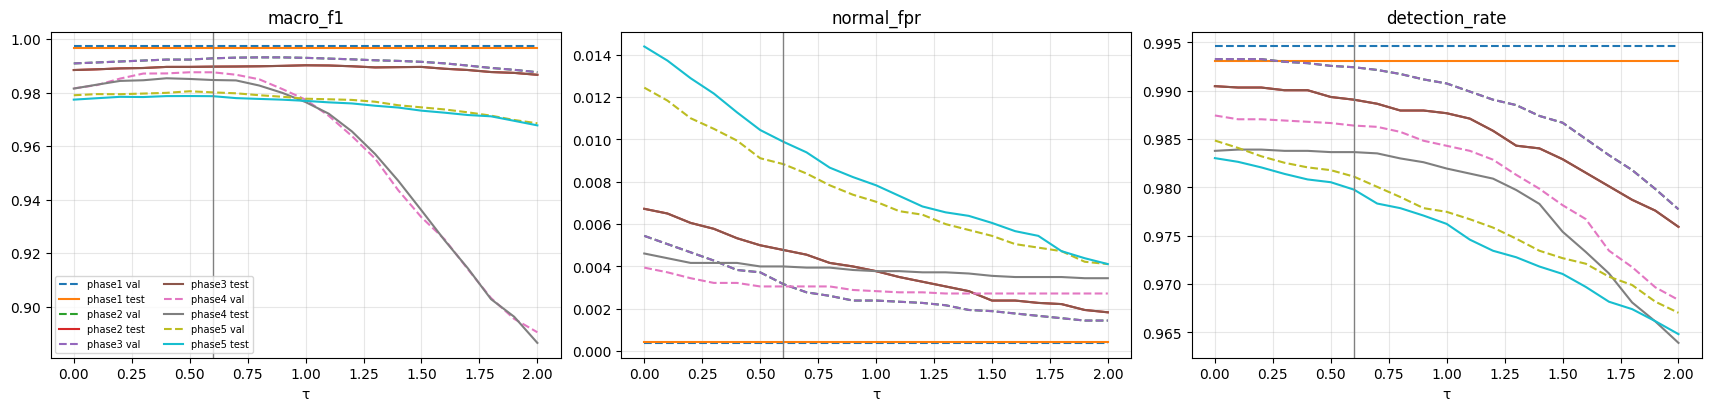

In [8]:
curve = []
for p in INFO:
    for t in TAUS:
        s = shift_prior(p, t)
        for split in ("val", "test"):
            r = evaluate(p, split, s)
            curve.append({"phase": p, "tau": t, "split": split,
                          "macro_f1": r["macro_f1"], "normal_fpr": r["normal_fpr"],
                          "detection_rate": r["detection_rate"]})
curve = pd.DataFrame(curve)

val_mean = curve[curve.split == "val"].groupby("tau")["macro_f1"].mean()
TAU_GLOBAL = float(val_mean.idxmax())
tau_per_phase = (curve[curve.split == "val"].sort_values("macro_f1", ascending=False)
                 .groupby("phase").head(1).set_index("phase")["tau"])
print(f"τ chung (chọn trên val): {TAU_GLOBAL}")
print("τ tốt nhất riêng từng phase (val):", tau_per_phase.to_dict())

fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
for ax, metric in zip(axes, ["macro_f1", "normal_fpr", "detection_rate"]):
    for p in INFO:
        for split, ls in (("val", "--"), ("test", "-")):
            g = curve[(curve.phase == p) & (curve.split == split)]
            ax.plot(g["tau"], g[metric], ls=ls, label=f"{p} {split}" if metric == "macro_f1" else None)
    ax.axvline(TAU_GLOBAL, color="gray", lw=1)
    ax.set_xlabel("τ"); ax.set_title(metric); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
plt.show()

## 7. Kết quả trên test: trước và sau hiệu chỉnh

In [9]:
METHODS = {
    "none": lambda p: np.zeros(NC),
    f"prior τ={TAU_GLOBAL}": lambda p: shift_prior(p, TAU_GLOBAL),
    "bias_fit": fit_bias,
}
SHIFTS = {m: {p: f(p) for p in INFO} for m, f in METHODS.items()}

res = []
for m in METHODS:
    for p in INFO:
        r = evaluate(p, "test", SHIFTS[m][p])
        res.append({"method": m, "phase": p, **r})
res = pd.DataFrame(res)

main_cols = ["macro_f1", "normal_fpr", "detection_rate", "newest_precision"]
display(res.pivot(index="phase", columns="method", values=main_cols)
        .style.format("{:.4f}", na_rep=""))

In [10]:
cls_cols = [c for c in CLASS_NAMES if c in res.columns]
for m in METHODS:
    print(f"\n=== F1 từng lớp: {m} ===")
    t = res[res.method == m].set_index("phase")[cls_cols]
    display(t.style.format("{:.4f}", na_rep="").background_gradient(
        cmap="RdYlGn", vmin=0.88, vmax=1.0, axis=None))


=== F1 từng lớp: none ===


,normal,dos,fuzzing,gear,interval,rpm,speed,standstill,systematic,combined
phase,,,,,,,,,,
phase1,0.9988,0.9991,0.9937,0.9931,0.9986,0.9963,,,,
phase2,0.9947,0.9991,0.9876,0.9909,0.9945,0.9942,0.9581,,,
phase3,0.9947,0.9991,0.9876,0.9909,0.9945,0.9942,0.9581,,,
phase4,0.9943,0.9991,0.9852,0.9916,0.9908,0.9784,0.9585,0.9542,,
phase5,0.9879,0.9991,0.9759,0.9916,0.9949,0.9894,0.9713,0.9769,0.9609,0.9260



=== F1 từng lớp: prior τ=0.6 ===


,normal,dos,fuzzing,gear,interval,rpm,speed,standstill,systematic,combined
phase,,,,,,,,,,
phase1,0.9988,0.9991,0.9937,0.9931,0.9986,0.9963,,,,
phase2,0.9954,0.9991,0.9876,0.9902,0.9949,0.9936,0.9671,,,
phase3,0.9954,0.9991,0.9876,0.9902,0.9949,0.9936,0.9671,,,
phase4,0.9945,0.9991,0.9852,0.9916,0.9908,0.9852,0.9581,0.9731,,
phase5,0.9892,0.9991,0.9758,0.9916,0.9954,0.9894,0.9721,0.9769,0.9602,0.9371



=== F1 từng lớp: bias_fit ===


,normal,dos,fuzzing,gear,interval,rpm,speed,standstill,systematic,combined
phase,,,,,,,,,,
phase1,0.9987,0.9991,0.9932,0.9931,0.9986,0.9963,,,,
phase2,0.9957,0.9991,0.9895,0.9901,0.9954,0.9931,0.9679,,,
phase3,0.9957,0.9991,0.9895,0.9901,0.9954,0.9931,0.9679,,,
phase4,0.9948,0.9991,0.9871,0.9924,0.9926,0.9867,0.9600,0.9733,,
phase5,0.9892,0.9991,0.9775,0.9924,0.9954,0.9899,0.9714,0.9820,0.9618,0.9357


## 8. Confusion matrix trước và sau

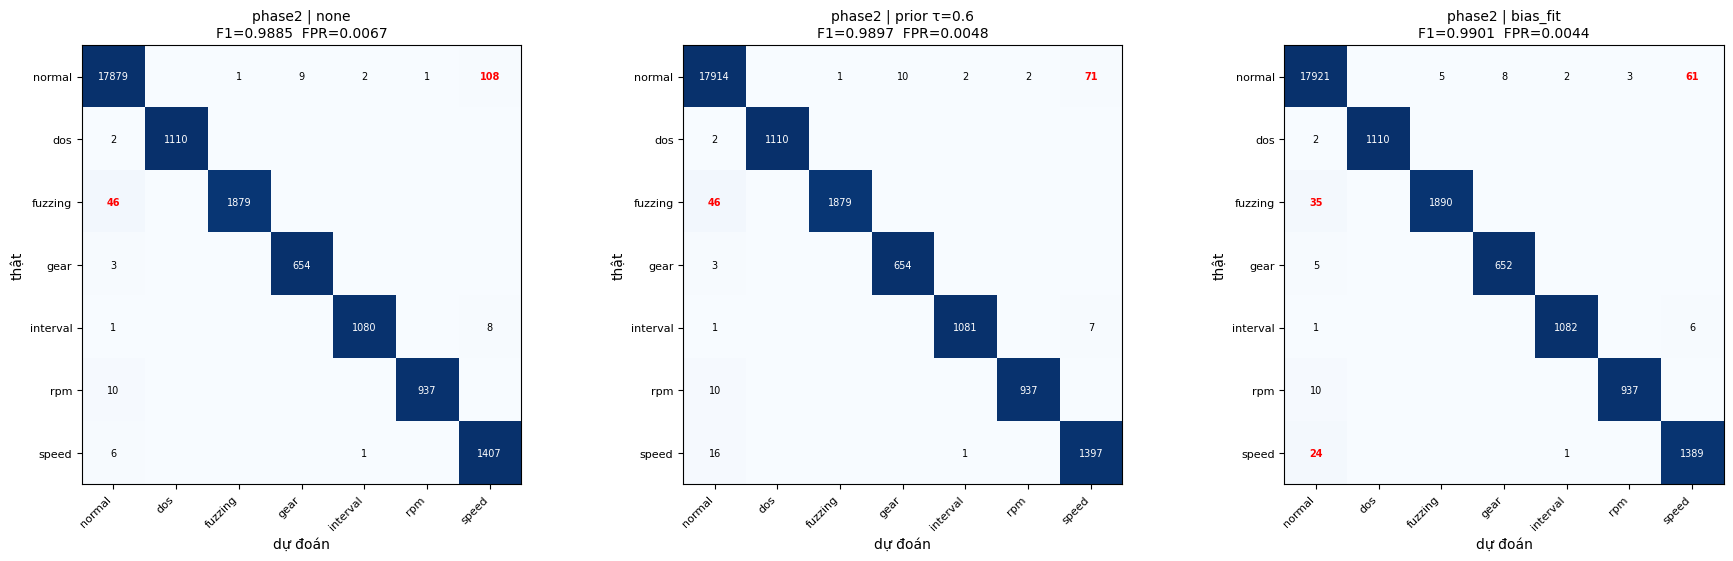

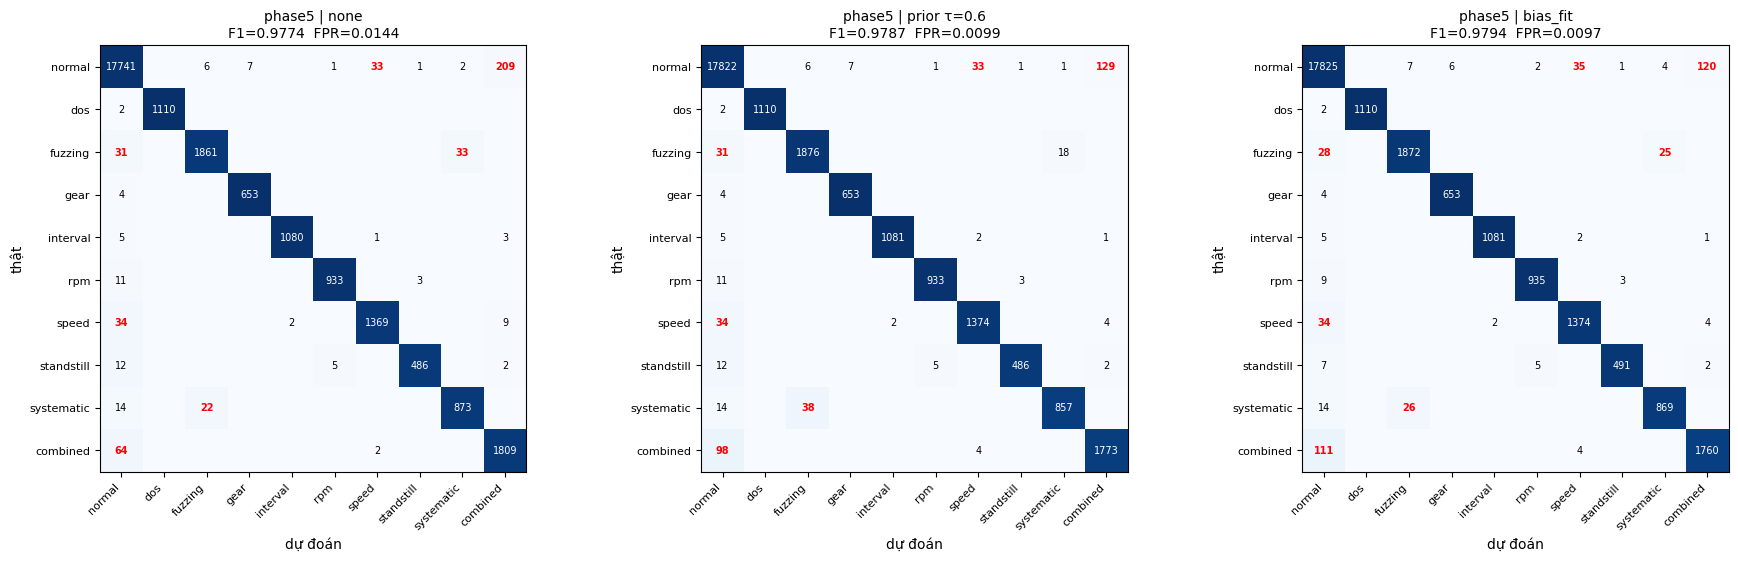

In [11]:
def plot_cm(ax, y, pred, seen, title):
    labels = [CLASS_NAMES[c] for c in seen]
    pos = {c: i for i, c in enumerate(seen)}
    cm = np.zeros((len(seen), len(seen)), dtype=int)
    for a, b in zip(y, pred):
        cm[pos[a], pos[b]] += 1
    norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(seen)):
        for j in range(len(seen)):
            if cm[i, j]:
                off = i != j
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="red" if off and cm[i, j] >= 20 else ("white" if norm[i, j] > 0.5 else "black"),
                        fontweight="bold" if off and cm[i, j] >= 20 else "normal")
    ax.set_xticks(range(len(seen)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(seen)), labels, fontsize=8)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("thật"); ax.set_title(title, fontsize=10)

for p in CM_PHASES:
    fig, axes = plt.subplots(1, len(METHODS), figsize=(6 * len(METHODS), 5.5), constrained_layout=True)
    for ax, m in zip(axes, METHODS):
        r = res[(res.method == m) & (res.phase == p)].iloc[0]
        plot_cm(ax, r["_y"], r["_pred"], INFO[p]["seen"],
                f"{p} | {m}\nF1={r['macro_f1']:.4f}  FPR={r['normal_fpr']:.4f}")
    plt.show()

## 9. Bias học được có khớp với lệch prior không?
Nếu nguyên nhân là lệch prior, bias học trên val (trục y) phải đi cùng chiều với log(π_val / π_train) (trục x). Hệ số tương quan cao và dương ủng hộ giả thuyết.

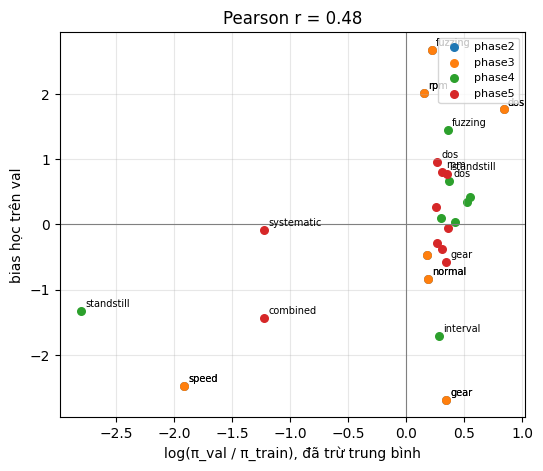

In [12]:
pts = []
for p, d in INFO.items():
    if p == "phase1":
        continue
    x = shift_prior(p, 1.0)
    b = SHIFTS["bias_fit"][p]
    seen = d["seen"]
    x_c = x[seen] - x[seen].mean()
    for c, xv, bv in zip(seen, x_c, b[seen]):
        pts.append({"phase": p, "class": CLASS_NAMES[c], "log_prior_ratio": xv, "learned_bias": bv})
pts = pd.DataFrame(pts)

fig, ax = plt.subplots(figsize=(6, 5))
for p, g in pts.groupby("phase"):
    ax.scatter(g["log_prior_ratio"], g["learned_bias"], label=p, s=30)
    for _, r in g.iterrows():
        if abs(r["learned_bias"]) > 0.5 or abs(r["log_prior_ratio"]) > 1.0:
            ax.annotate(r["class"], (r["log_prior_ratio"], r["learned_bias"]), fontsize=7,
                        xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("log(π_val / π_train), đã trừ trung bình")
ax.set_ylabel("bias học trên val")
r_all = np.corrcoef(pts["log_prior_ratio"], pts["learned_bias"])[0, 1]
ax.set_title(f"Pearson r = {r_all:.2f}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

## 10. Lưu kết quả

In [ ]:
out = res.drop(columns=["_pred", "_y"])
out.to_csv(NOTEBOOK_DIR / "logit_adjustment_results.csv", index=False)
curve.to_csv(NOTEBOOK_DIR / "logit_adjustment_tau_curve.csv", index=False)
print("Đã lưu vào", NOTEBOOK_DIR)

## 11. Đọc kết quả và quyết định

| Kết quả | Kết luận | Bước tiếp |
|---|---|---|
| Prior correction giảm mạnh normal_FPR và tăng F1, `detection_rate` gần như giữ nguyên, r ở mục 9 cao | Lệch prior là nguyên nhân chính | Bước 2: đưa vào lúc huấn luyện (logit-adjusted CE hoặc replay cân bằng) |
| Chỉ bias_fit cải thiện, prior correction thì không | Có bias theo lớp nhưng không do tỷ lệ dữ liệu | Hiệu chỉnh classifier (BiC/WA) thay vì sửa dữ liệu |
| Cả hai đều cải thiện ít | Lỗi nằm ở biểu diễn, không ở ranh giới | Quay lại hướng tăng epoch và ổn định routing |

Hai lưu ý khi báo cáo:

- τ và bias được chọn trên val, chỉ test mới được dùng để báo cáo. Không chỉnh τ theo test.
- Hiệu chỉnh đánh đổi báo động giả lấy bỏ sót. Luôn đặt `normal_fpr` cạnh `detection_rate`. Nếu `detection_rate` giảm nhiều hơn mức FPR giảm, cách hiệu chỉnh đó không có lợi cho IDS dù macro F1 tăng.